# Background Subtraction

A temporal median estimates a static background from noisy frames containing a moving disk. Subsequent frames supply an independent mask test.

In [1]:
from pathlib import Path
import sys

start = Path.cwd()
for parent in (start, *start.parents):
    if (parent / "gallery" / "__init__.py").is_file():
        sys.path.insert(0, str(parent))
        break
else:
    raise RuntimeError("Open this example inside the Machine Learning collection.")

## Generate a fixed-camera sequence

A disk occupies a new location in each frame over a fixed textured background.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from gallery.vision import binary_mask_scores


def frame_bank(n, seed, background):
    rng = np.random.default_rng(seed)
    yy, xx = np.indices(background.shape)
    images = []
    masks = []
    for i in range(n):
        x = rng.integers(5, background.shape[1] - 5)
        y = rng.integers(5, background.shape[0] - 5)
        mask = (xx - x) ** 2 + (yy - y) ** 2 < 24
        images.append(
            np.clip(background + 0.48 * mask + rng.normal(0, 0.055, background.shape), 0, 1)
        )
        masks.append(mask)
    return np.stack(images), np.stack(masks)

## Score foreground pixels

The median uses forty background-estimation frames. Test frames do not contribute to it.

Mean IoU: 0.993
Mean Dice: 0.997
Pixel precision: 0.993
Pixel recall: 1.000
Pixel accuracy: 1.000


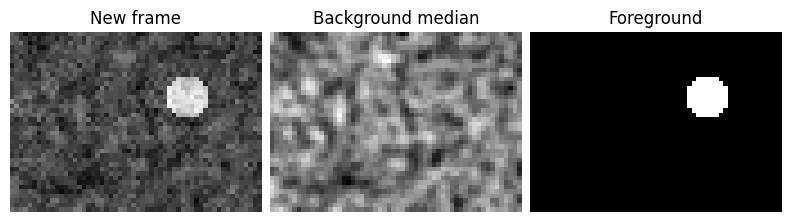

In [3]:
rng = np.random.default_rng(17)
bg = 0.30 + gaussian_filter(rng.normal(size=(40, 56)), 1) * 0.18
train, _ = frame_bank(40, 19, bg)
test, truth = frame_bank(70, 83, bg)
median = np.median(train, axis=0)
pred = abs(test - median) > 0.21
for label, value in binary_mask_scores(truth, pred).items():
    print(f"{label}: {value:.3f}")
fig, axes = plt.subplots(1, 3, figsize=(7.8, 2.4), constrained_layout=True)
for a, im, title in zip(
    axes, [test[0], median, pred[0]], ["New frame", "Background median", "Foreground"]
):
    a.imshow(im, cmap="gray")
    a.set_title(title)
    a.axis("off")
plt.show()

## Reading the result

The method assumes that the background occupies a pixel for most of the reference frames. A stationary foreground object breaks that assumption.

## References

[Piccardi, Background subtraction techniques: a review (2004)](https://doi.org/10.1109/ICSMC.2004.1400815)

[Image and video generators and evaluation](../../../gallery/vision.py)